# Optimisation Random Forest avec Optuna

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Chargement des données

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## 2. Analyse exploratoire

In [3]:
print(df.shape)
df.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


In [4]:
print(df.isnull().sum())
print(df.duplicated().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
0


## 3. Identification et traitement des valeurs manquantes

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df['TotalCharges'].isnull().sum())

11


In [6]:
df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [7]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print(df['TotalCharges'].isnull().sum())

0


In [8]:
df = df.drop('customerID', axis=1)
df.shape

(7043, 20)

In [9]:
freq = df['Churn'].value_counts()
print(freq)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


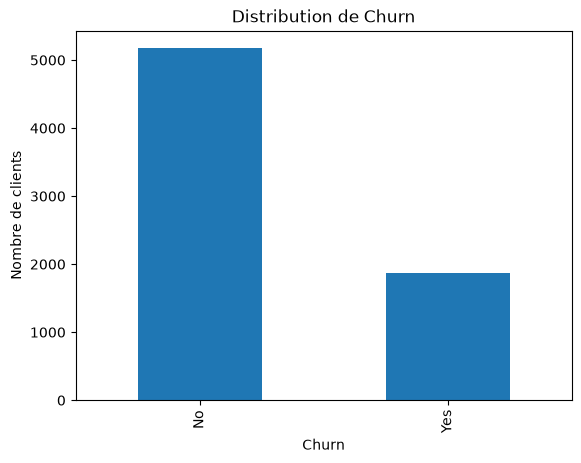

In [10]:
freq.plot(kind='bar')
plt.title('Distribution de Churn')
plt.xlabel('Churn')
plt.ylabel('Nombre de clients')
plt.show()

Dataset de 7043 clients, 21 colonnes. La variable cible 'Churn' est déséquilibrée, environ 73.5% de clients restent ("No") contre 26.5% qui résilient ("Yes").

## 4. Traitement des variables catégorielles et encodage de la cible

In [11]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns
print(cat_cols)

for col in cat_cols:
    print(col, ':', df[col].unique())

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')
gender : <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner : <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService : <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity : <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup : <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection : <ArrowStringArray>
['No', 'Yes', 'No internet 

In [12]:
from sklearn.preprocessing import LabelEncoder

def categorical_features(df):
    object_columns = df.select_dtypes(include=['object', 'str']).columns
    label_encoder = LabelEncoder()
    for col in object_columns:
        df[col] = label_encoder.fit_transform(df[col])
    return df

df = categorical_features(df)
df.dtypes

gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

In [13]:
X = df.drop('Churn', axis=1)
y = df['Churn']


## 5. Normalisation et préparation des ensembles train/validation/test

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.5, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.6, random_state=42, stratify=y_temp)


Split en 50% train / 20% validation / 30% test

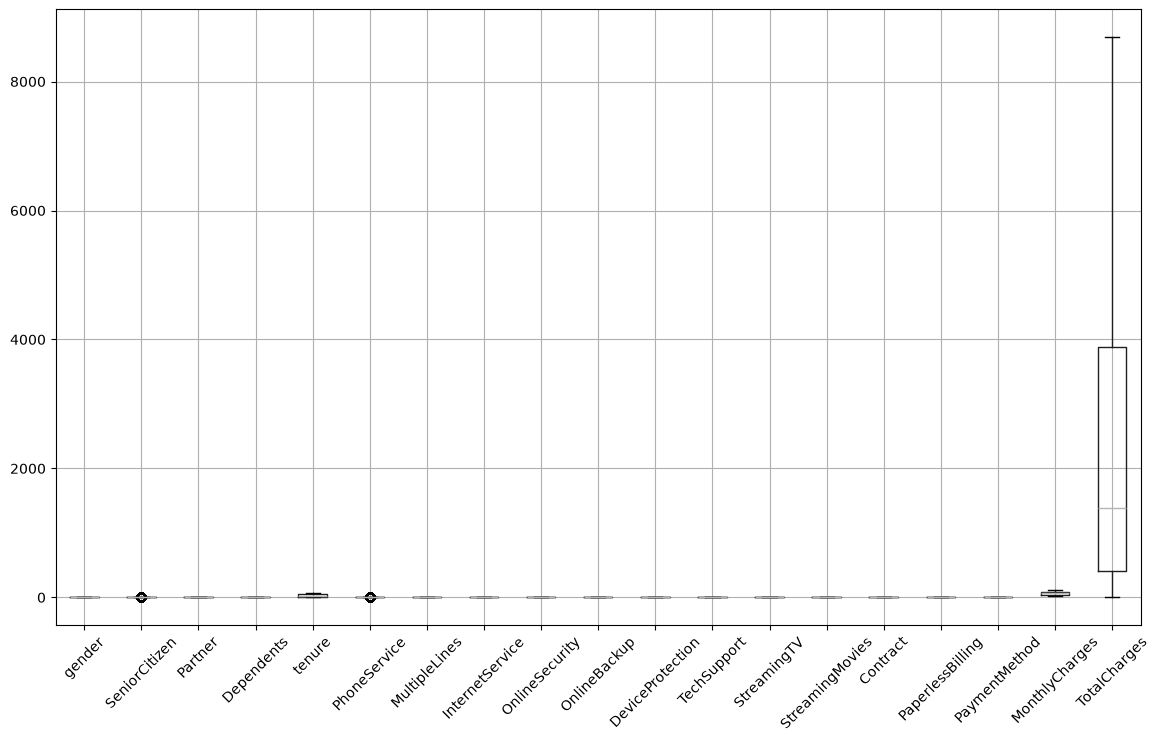

gender                 0.505254
SeniorCitizen          0.160182
Partner                0.489066
Dependents             0.304743
tenure                32.626243
PhoneService           0.902016
MultipleLines          0.946606
InternetService        0.880432
OnlineSecurity         0.795797
OnlineBackup           0.920761
DeviceProtection       0.924169
TechSupport            0.819085
StreamingTV            1.013348
StreamingMovies        1.003124
Contract               0.706049
PaperlessBilling       0.584777
PaymentMethod          1.567168
MonthlyCharges        65.031341
TotalCharges        2311.495640
dtype: float64
gender                 0.500043
SeniorCitizen          0.366827
Partner                0.499951
Dependents             0.460364
tenure                24.624568
PhoneService           0.297335
MultipleLines          0.948378
InternetService        0.737522
OnlineSecurity         0.859799
OnlineBackup           0.880162
DeviceProtection       0.880462
TechSupport            0.

In [15]:
plt.figure(figsize=(14, 8))
X_train.boxplot()
plt.xticks(rotation=45)
plt.show()

print(X_train.mean())
print(X_train.std())

Le boxplot montre que 'TotalCharges' monte jusqu'à ~9000 alors que les colonnes encodées sont minimes. Sans normalisation, le modèle donnerait trop d'importance à 'TotalCharges' juste à cause de son échelle. Le StandardScaler met toutes les colonnes à la même échelle pour éviter ça.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [17]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [18]:
print(df.dtypes)

gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService       int64
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract              int64
PaperlessBilling      int64
PaymentMethod         int64
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


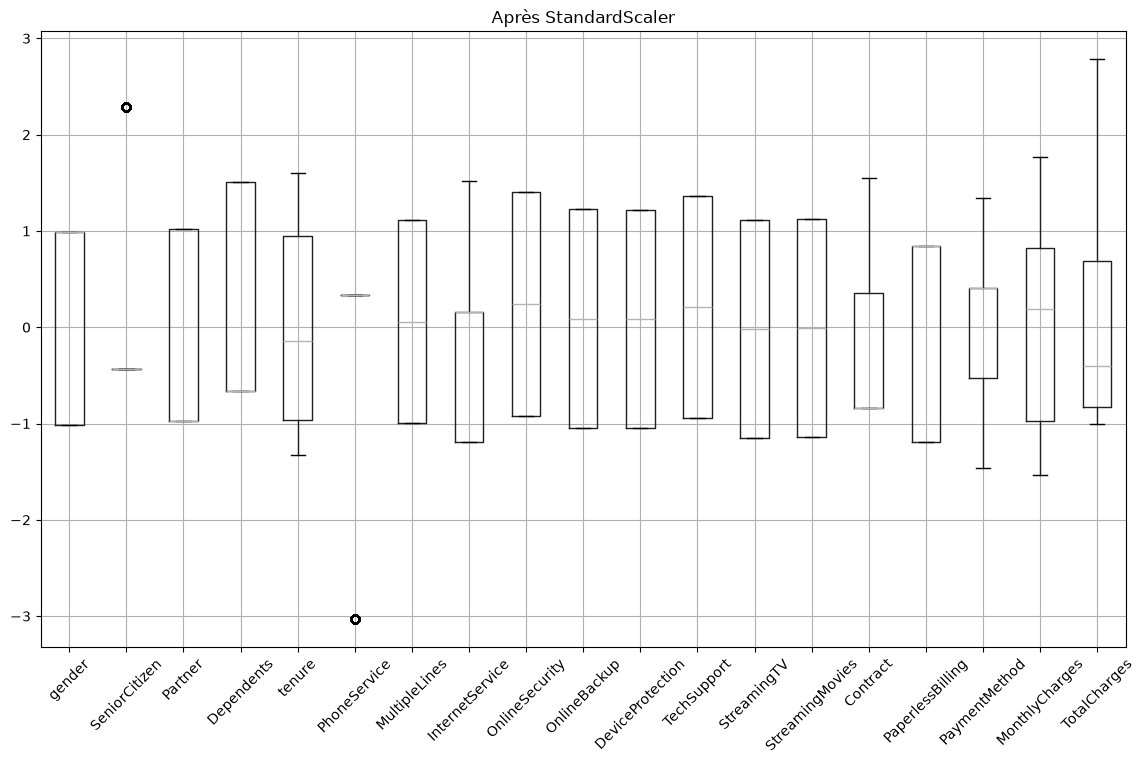

In [19]:
pd.DataFrame(X_train_scaled, columns=X_train.columns).boxplot(figsize=(14, 8))
plt.xticks(rotation=45)
plt.title('Après StandardScaler')
plt.show()

Le dataset est prêt pour la modélisation. Les valeurs manquantes ont été traitées, les variables catégorielles ont été encodées, et les données ont été divisées en ensembles train / validation / test (50% / 20% / 30%) puis normalisées avec StandardScaler.

## 6. Configuration du serveur MLflow

In [22]:
import mlflow

mlflow.set_tracking_uri(uri="http://127.0.0.1:5000")
mlflow.set_experiment("Telco_Customer_Churn_Optuna")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1795767104732, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795767104732, lifecycle_stage='active', name='Telco_Customer_Churn_Optuna', tags={}, trace_location=None, workspace='default'>

## 7. Optimisation du Random Forest avec Optuna

In [23]:
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve)

In [26]:
def objective(trial):
    with mlflow.start_run(nested=True, run_name=f"trial_{trial.number}") as child_run:
        n_estimators = trial.suggest_int("n_estimators", 50, 300)
        max_depth = trial.suggest_int("max_depth", 3, 20)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
        max_features = trial.suggest_categorical("max_features", ["sqrt", "log2"])
        class_weight = trial.suggest_categorical("class_weight", [None, "balanced"])

        params = {
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "min_samples_split": min_samples_split,
            "min_samples_leaf": min_samples_leaf,
            "max_features": max_features,
            "class_weight": class_weight,
        }

        model = RandomForestClassifier(**params, random_state=42)
        model.fit(X_train_scaled, y_train)

        pred = model.predict(X_val_scaled)
        pred_proba = model.predict_proba(X_val_scaled)[:, 1]

        accuracy = accuracy_score(y_val, pred)
        precision = precision_score(y_val, pred)
        recall = recall_score(y_val, pred)
        f1 = f1_score(y_val, pred)
        roc_auc = roc_auc_score(y_val, pred_proba)

        print("accuracy", accuracy)
        print("precision", precision)
        print("recall", recall)
        print("F1", f1)
        print("ROC-AUC", roc_auc)

        mlflow.log_params(params)
        mlflow.log_metrics({
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1,
            "roc_auc": roc_auc,
        })
        mlflow.sklearn.log_model(model, name="model", skops_trusted_types=["sklearn.tree._tree.Tree"])

        matrice = confusion_matrix(y_val, pred)
        print(matrice)
        plt.figure()
        sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
        plt.title('Matrice de confusion')
        plt.xlabel('Prédit')
        plt.ylabel('Réel')
        plt.savefig('confusion_matrix.png')
        plt.close()
        mlflow.log_artifact('confusion_matrix.png')

        fpr, tpr, _ = roc_curve(y_val, pred_proba)
        plt.figure()
        plt.plot(fpr, tpr, label='Random Forest')
        plt.plot([0, 1], [0, 1], color='black', linestyle='--')
        plt.xlabel('Proportion mal classée')
        plt.ylabel('Proportion bien classée')
        plt.title('Courbe ROC')
        plt.legend(loc='lower right')
        plt.savefig('roc_curve.png')
        plt.close()
        mlflow.log_artifact('roc_curve.png')

        trial.set_user_attr("run_id", child_run.info.run_id)

    return f1

In [27]:
with mlflow.start_run(run_name="study_RandomForest") as run:
    n_trials = 30
    mlflow.log_param("n_trials", n_trials)

    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=n_trials)

    mlflow.log_params(study.best_trial.params)
    mlflow.log_metrics({"best_f1_score": study.best_value})
    if best_run_id := study.best_trial.user_attrs.get("run_id"):
        mlflow.log_param("best_child_run_id", best_run_id)

[I 2026-11-27 09:40:50,192] A new study created in memory with name: no-name-0f3b21d7-b6f6-4ec6-934b-a8ede4625464
2026/11/27 09:40:50 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP


accuracy 0.7365056818181818
precision 0.502454991816694
recall 0.820855614973262
F1 0.6233502538071066
ROC-AUC 0.8441944476049607


2026/11/27 09:40:50 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP
2026/11/27 09:40:50 INFO mlflow.utils.environment: Detected uv project at /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP. Attempting to export requirements via 'uv export'.
2026/11/27 09:40:51 INFO mlflow.utils.uv_utils: Exported 176 dependencies via uv
2026/11/27 09:40:51 INFO mlflow.utils.environment: Successfully exported 176 requirements from uv project. Skipping package capture based inference.
2026/11/27 09:40:51 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


[[730 304]
 [ 67 307]]


[I 2026-11-27 09:40:52,312] Trial 0 finished with value: 0.6233502538071066 and parameters: {'n_estimators': 210, 'max_depth': 6, 'min_samples_split': 2, 'min_samples_leaf': 7, 'max_features': 'sqrt', 'class_weight': 'balanced'}. Best is trial 0 with value: 0.6233502538071066.


🏃 View run trial_0 at: http://127.0.0.1:5000/#/experiments/1/runs/735674a101f44f389a6c9c663694d174
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
accuracy 0.8032670454545454
precision 0.6644067796610169
recall 0.5240641711229946
F1 0.585949177877429
ROC-AUC 0.8428045387312653


... (112 outputs left out)

2026/11/27 09:41:18 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP
2026/11/27 09:41:19 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP
2026/11/27 09:41:19 INFO mlflow.utils.environment: Detected uv project at /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP. Attempting to export requirements via 'uv export'.


accuracy 0.7954545454545454
precision 0.6493055555555556
recall 0.5
F1 0.5649546827794562
ROC-AUC 0.8382546881949544


2026/11/27 09:41:19 INFO mlflow.utils.uv_utils: Exported 176 dependencies via uv
2026/11/27 09:41:19 INFO mlflow.utils.environment: Successfully exported 176 requirements from uv project. Skipping package capture based inference.
2026/11/27 09:41:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
[I 2026-11-27 09:41:19,366] Trial 29 finished with value: 0.5649546827794562 and parameters: {'n_estimators': 84, 'max_depth': 20, 'min_samples_split': 19, 'min_samples_leaf': 9, 'max_features': 'log2', 'class_weight': None}. Best is trial 11 with value: 0.6339381003201707.


[[933 101]
 [187 187]]
🏃 View run trial_29 at: http://127.0.0.1:5000/#/experiments/1/runs/fe73b369edd04880885a0d47a8ee3bc6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run study_RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/309d6705f28a4621b21208bd96a842d0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## 8. Évaluation finale du meilleur modèle

In [30]:
best_params = study.best_trial.params
print("Meilleurs hyperparametres :", best_params)
print("Meilleur F1-score :", study.best_value)

X_train_val_scaled = np.vstack([X_train_scaled, X_val_scaled])
y_train_val = pd.concat([y_train, y_val])

with mlflow.start_run(run_name="best_model_RandomForest") as run:
    final_model = RandomForestClassifier(**best_params, random_state=42)
    final_model.fit(X_train_val_scaled, y_train_val)

    pred = final_model.predict(X_test_scaled)
    pred_proba = final_model.predict_proba(X_test_scaled)[:, 1]

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)

    print("accuracy", accuracy)
    print("precision", precision)
    print("recall", recall)
    print("F1", f1)
    print("ROC-AUC", roc_auc)

    mlflow.log_params(best_params)
    mlflow.log_metrics({
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": roc_auc,
    })
    mlflow.sklearn.log_model(final_model, name="model", skops_trusted_types=["sklearn.tree._tree.Tree"])

    matrice = confusion_matrix(y_test, pred)
    print(matrice)
    plt.figure()
    sns.heatmap(matrice, annot=True, fmt='d', cmap='Blues')
    plt.title('Matrice de confusion - Test')
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.savefig('confusion_matrix_final.png')
    plt.close()
    mlflow.log_artifact('confusion_matrix_final.png')

    fpr, tpr, _ = roc_curve(y_test, pred_proba)
    plt.figure()
    plt.plot(fpr, tpr, label='Random Forest')
    plt.plot([0, 1], [0, 1], color='black', linestyle='--')
    plt.xlabel('Proportion mal classée')
    plt.ylabel('Proportion bien classée')
    plt.title('Courbe ROC - Test')
    plt.legend(loc='lower right')
    plt.savefig('roc_curve_final.png')
    plt.close()
    mlflow.log_artifact('roc_curve_final.png')

    run_id = run.info.run_id

print("Run ID :", run_id)

Meilleurs hyperparametres : {'n_estimators': 131, 'max_depth': 16, 'min_samples_split': 17, 'min_samples_leaf': 9, 'max_features': 'log2', 'class_weight': 'balanced'}
Meilleur F1-score : 0.6339381003201707


2026/11/27 09:52:53 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP


accuracy 0.760643330179754
precision 0.5334957369062119
recall 0.7807486631016043
F1 0.6338639652677279
ROC-AUC 0.8401914298471246


2026/11/27 09:52:54 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP
2026/11/27 09:52:54 INFO mlflow.utils.environment: Detected uv project at /Users/joaopauloguerra/Desktop/Inge3/GestionprojetIA/TP. Attempting to export requirements via 'uv export'.
2026/11/27 09:52:54 INFO mlflow.utils.uv_utils: Exported 176 dependencies via uv
2026/11/27 09:52:54 INFO mlflow.utils.environment: Successfully exported 176 requirements from uv project. Skipping package capture based inference.
2026/11/27 09:52:54 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


[[1170  383]
 [ 123  438]]
🏃 View run best_model_RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/2c333932a6ef465fb0dec66c7dfa3cc6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run ID : 2c333932a6ef465fb0dec66c7dfa3cc6


In [31]:
model_name = "random_forest_churn"

result = mlflow.register_model(
    model_uri=f"runs:/{run_id}/model",
    name=model_name
)

print("Modele enregistre :", result.name, "version", result.version)

Successfully registered model 'random_forest_churn'.
2026/11/27 09:55:00 WARNING mlflow.tracking._model_registry.fluent: Run with id 2c333932a6ef465fb0dec66c7dfa3cc6 has no artifacts at artifact path 'model', registering model based on models:/m-a53f9a111c854bc98ae2c09c057b5880 instead
2026/11/27 09:55:00 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: random_forest_churn, version 1


Modele enregistre : random_forest_churn version 1


Created version '1' of model 'random_forest_churn'.


## 9. Conclusion

Le meilleur modèle Random Forest (trial 11, F1 validation = 0.6339).

**Hyperparamètres retenus** : 
- n_estimators=131
- max_depth=16
- min_samples_split=17
- min_samples_leaf=9
- max_features='log2', class_weight='balanced'

**Résultats sur Test** :
- F1-score : 0.6339 (identique à la validation, pas de signe de surapprentissage)
- Accuracy : 0.7606
- Precision : 0.5335
- Recall : 0.7807
- ROC-AUC : 0.8402


Le modèle final a été enregistré dans le MLflow Model Registry sous le nom 'random_forest_churn'